# Round 1 transfer: models trained on monkey N, evaluated on monkey F

Question: does aligning layer8 to monkey N's IT also make it more similar to monkey F's IT?

- Models: Round 1 control, student w0.1, student w1 (trained on monkey N only), epochs 0-10; epoch 0 = pretrained
- Evaluation: val split (images never trained on, same split for both monkeys), batches of 64 from one recording day of the evaluated monkey, pooled CKA_S
- Monkey N: evaluation during training (`<run>/eval/`); monkey F: `transfer/eval_other_monkey.py` (`<run>/eval_monkeyF/`)
- Response windows: V1 20-200 ms, V4 50-200 ms, IT 70-200 ms (IT window = the CKA loss bins)
- Compare gains over the pretrained model, not absolute values (monkey F's signal is weaker)

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=RuntimeWarning)

ROUND1 = Path("~/Desktop/DynVision/CordsNet/Round1").expanduser()
RUNS_DIR = ROUND1 / "outputs" / "round1"
runs = ["control", "student_IT_layer8_w0p1", "student_IT_layer8_w1"]
label = {"pretrained": "pretrained", "control": "control",
         "student_IT_layer8_w0p1": "student w0.1", "student_IT_layer8_w1": "student w1"}
color = {"pretrained": "0.35", "control": "#2a78d6",
         "student_IT_layer8_w0p1": "#eb6834", "student_IT_layer8_w1": "#1baf7a"}
monkeys = {"monkeyN": "eval", "monkeyF": "eval_monkeyF"}

ev = {m: {run: [np.load(f) for f in sorted((RUNS_DIR / run / folder).glob("epoch_*.npz"))] for run in runs}
      for m, folder in monkeys.items()}
n_epochs = len(ev["monkeyF"]["control"]) - 1
r0 = ev["monkeyF"]["control"][0]
layers, areas, ests = [[str(x) for x in r0[k]] for k in ("layers", "areas", "estimators")]
S = ests.index("CKA_S")
t_ms = r0["bin_start_ms"] + 5
li, aj = layers.index("layer8"), areas.index("IT")
window = {"V1": np.arange(2, 20), "V4": np.arange(5, 20), "IT": np.arange(7, 20)}

# IT-layer8 CKA_S over the IT window, per monkey, run and epoch
it8 = {m: {run: np.array([np.nanmean(e["cka_pooled"][li, aj, window["IT"], S]) for e in ev[m][run]]) for run in runs}
       for m in monkeys}

# checks: epoch 0 identical across runs; monkey F epoch 0 = the separate epoch-0 run
e0 = np.load(ROUND1 / "outputs" / "epoch0_pretrained_monkeyF" / "results.npz")
print("epochs per run:", {m: {label[r]: len(ev[m][r]) for r in runs} for m in monkeys})
print("F epoch 0 identical across runs:",
      all(np.allclose(ev["monkeyF"][r][0]["cka_pooled"], r0["cka_pooled"], equal_nan=True) for r in runs))
print("F epoch 0 = epoch0_pretrained_monkeyF: max |diff| =",
      np.nanmax(np.abs(r0["cka_pooled"][..., S] - e0["cka_pooled"][..., S])))
print(f"F: {len(r0['batch_day'])} val batches, N: {len(ev['monkeyN']['control'][0]['batch_day'])}")

epochs per run: {'monkeyN': {'control': 11, 'student w0.1': 11, 'student w1': 11}, 'monkeyF': {'control': 11, 'student w0.1': 11, 'student w1': 11}}
F epoch 0 identical across runs: True
F epoch 0 = epoch0_pretrained_monkeyF: max |diff| = 0.0
F: 27 val batches, N: 27


## 1. Transfer over training

IT vs layer8, CKA_S over 70-200 ms. Left: absolute. Right: gain over epoch 0 (pretrained).
Solid: monkey N (trained on), dashed: monkey F (never trained on).

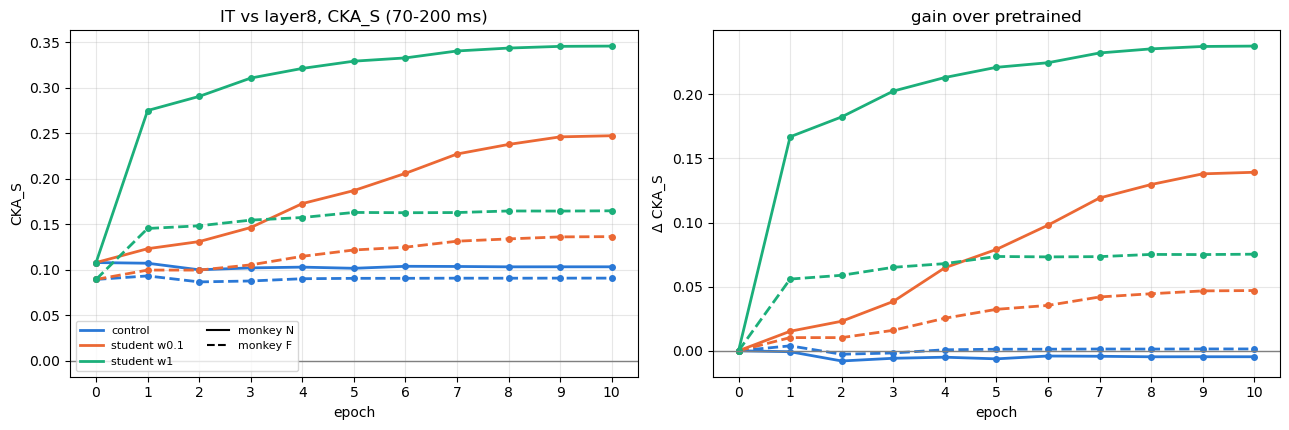

epoch 10, IT vs layer8 CKA_S (70-200 ms):
                      N       F      ΔN      ΔF   ΔF/ΔN
  control         0.103   0.091  -0.005  +0.001     nan
  student w0.1    0.247   0.137  +0.139  +0.047    0.34
  student w1      0.346   0.165  +0.238  +0.075    0.32
  pretrained      0.108   0.090


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for run in runs:
    for m, style in [("monkeyN", "o-"), ("monkeyF", "o--")]:
        y = it8[m][run]
        axes[0].plot(range(n_epochs + 1), y, style, color=color[run], lw=2, ms=4)
        axes[1].plot(range(n_epochs + 1), y - y[0], style, color=color[run], lw=2, ms=4)
for run in runs:
    axes[0].plot([], [], "-", color=color[run], lw=2, label=label[run])
axes[0].plot([], [], "k-", label="monkey N")
axes[0].plot([], [], "k--", label="monkey F")
axes[0].set(title="IT vs layer8, CKA_S (70-200 ms)", ylabel="CKA_S")
axes[1].set(title="gain over pretrained", ylabel="Δ CKA_S")
for ax in axes:
    ax.set(xlabel="epoch", xticks=range(n_epochs + 1))
    ax.axhline(0, color="0.5", lw=1)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

print(f"epoch {n_epochs}, IT vs layer8 CKA_S (70-200 ms):")
print(f"  {'':13s} {'N':>7s} {'F':>7s} {'ΔN':>7s} {'ΔF':>7s} {'ΔF/ΔN':>7s}")
for run in runs:
    n, f = it8["monkeyN"][run], it8["monkeyF"][run]
    dn, df = n[-1] - n[0], f[-1] - f[0]
    print(f"  {label[run]:13s} {n[-1]:7.3f} {f[-1]:7.3f} {dn:+7.3f} {df:+7.3f} {df / dn if abs(dn) > 0.01 else np.nan:7.2f}")
print(f"  {'pretrained':13s} {it8['monkeyN']['control'][0]:7.3f} {it8['monkeyF']['control'][0]:7.3f}")

## 2. When does the gain transfer?

IT vs layer8, CKA_S per bin, epoch 10. Gray: CKA loss bins. Left: monkey N, right: monkey F.

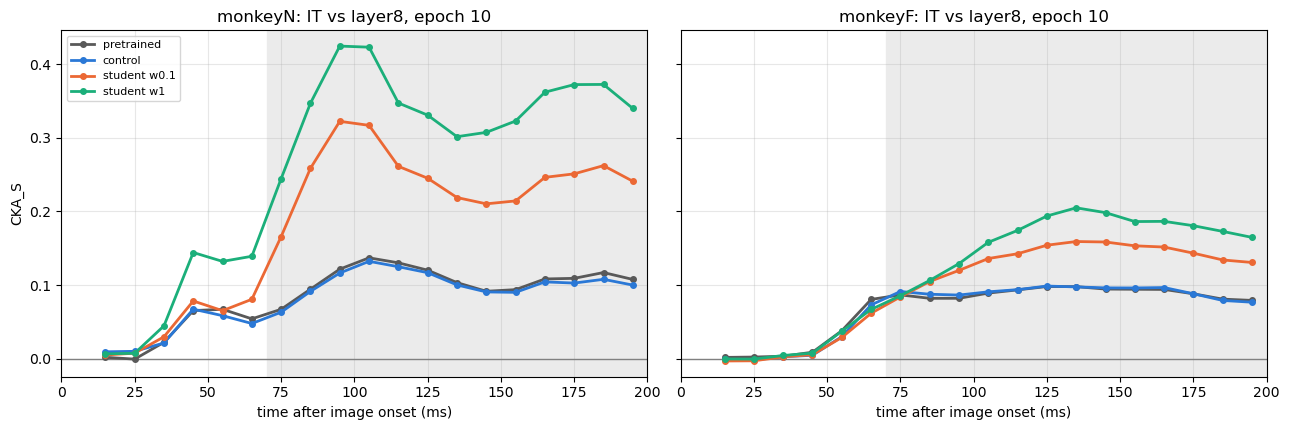

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, m in zip(axes, monkeys):
    ax.axvspan(window["IT"][0] * 10, 200, color="0.92", zorder=0)
    ax.axhline(0, color="0.5", lw=1)
    ax.plot(t_ms, ev[m]["control"][0]["cka_pooled"][li, aj, :, S], "o-", color=color["pretrained"], lw=2, ms=4, label="pretrained")
    for run in runs:
        ax.plot(t_ms, ev[m][run][-1]["cka_pooled"][li, aj, :, S], "o-", color=color[run], lw=2, ms=4, label=label[run])
    ax.set(title=f"{m}: IT vs layer8, epoch {n_epochs}", xlabel="time after image onset (ms)", xlim=(0, 200))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("CKA_S")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Other layers and areas on monkey F

Change in CKA_S (response window) from pretrained to epoch 10, per layer and area.

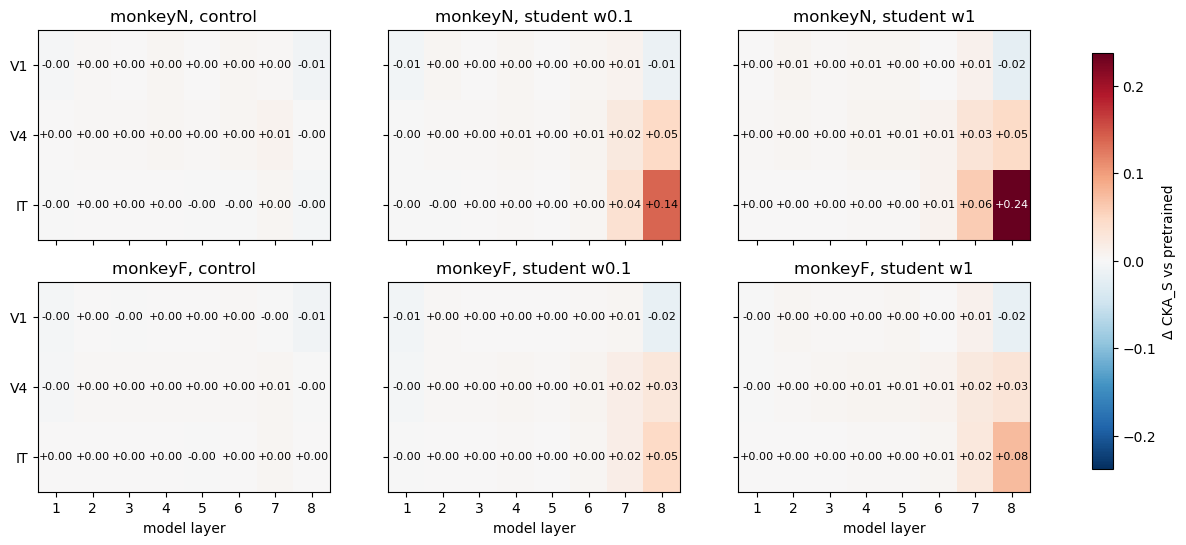

monkey F, pretrained CKA_S per layer (response window):
  V1: 0.130  0.215  0.179  0.121  0.107  0.088  0.096  0.092
  V4: 0.041  0.093  0.088  0.082  0.083  0.079  0.080  0.072
  IT: 0.037  0.062  0.067  0.067  0.079  0.090  0.097  0.090


In [4]:
win = {m: {run: np.array([[np.nanmean(e["cka_pooled"][i, j, window[a], S]) for j, a in enumerate(areas)]
                          for i in range(len(layers))]) for run, e in [(r, ev[m][r][-1]) for r in runs] + [("pretrained", ev[m]["control"][0])]}
       for m in monkeys}
delta = {m: {run: win[m][run] - win[m]["pretrained"] for run in runs} for m in monkeys}
lim = max(np.nanmax(np.abs(d)) for m in monkeys for d in delta[m].values())

fig, axes = plt.subplots(2, 3, figsize=(16, 6), sharex=True, sharey=True)
for row, m in enumerate(monkeys):
    for col, run in enumerate(runs):
        ax = axes[row, col]
        d = delta[m][run]
        im = ax.imshow(d.T, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
        for i in range(len(layers)):
            for j in range(len(areas)):
                ax.text(i, j, f"{d[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                        color="w" if abs(d[i, j]) > 0.6 * lim else "k")
        ax.set(title=f"{m}, {label[run]}", xticks=range(8), xticklabels=range(1, 9),
               yticks=range(len(areas)), yticklabels=areas)
    for ax in axes[1]:
        ax.set_xlabel("model layer")
fig.colorbar(im, ax=axes, label="Δ CKA_S vs pretrained", shrink=0.9)
plt.show()

print("monkey F, pretrained CKA_S per layer (response window):")
for j, a in enumerate(areas):
    print(f"  {a}: " + "  ".join(f"{v:.3f}" for v in win["monkeyF"]["pretrained"][:, j]))